In [1270]:
!uv sync

Resolved 118 packages in 2ms
Checked 114 packages in 12ms


## Librerías

In [1271]:
import cv2 as cv
import numpy as np
import os
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Rutas

In [1272]:
root = os.getcwd()

face_example = os.path.join(root, "faces/Approved/blue.png")
face_dir = os.path.join(root, "faces/Approved")

processed_dir = os.path.join(root, "Procesados")
os.makedirs(processed_dir, exist_ok=True)

gray_processed = os.path.join(processed_dir, "gray")
os.makedirs(gray_processed, exist_ok=True)

hsv_processed = os.path.join(processed_dir, "hsv")
os.makedirs(hsv_processed, exist_ok=True)

## Funciones

In [1273]:
def plot_single_image(images: list, titles: list[str], isgray: list[bool]):
    """
    Plot a list of images with the titles inside a list of strings
    """
    for i in range(len(images)):
        plt.subplot(2, 3, i+1)
        if isgray[i] == True:
            plt.imshow(images[i], cmap='gray')
        else:
            plt.imshow(images[i])
        plt.title(titles[i])
        plt.axis('off')
    plt.tight_layout()

def process_Otsu_image(img_path: str):
    img = cv.imread(img_path)

    imgGray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    ret,imgOtsu = cv.threshold(imgGray,0,255,cv.THRESH_BINARY+cv.THRESH_OTSU)

    return ret, imgOtsu

def process_HSV_image(img_path: str):
    img = cv.imread(img_path)

    imgHSV = cv.cvtColor(img, cv.COLOR_BGR2HSV)
    imgRecortada = imgHSV[:, :, 2]

    ret,imgOtsu = cv.threshold(imgRecortada,0,255,cv.THRESH_BINARY+cv.THRESH_OTSU)

    return ret, imgOtsu

## Binarización imagen

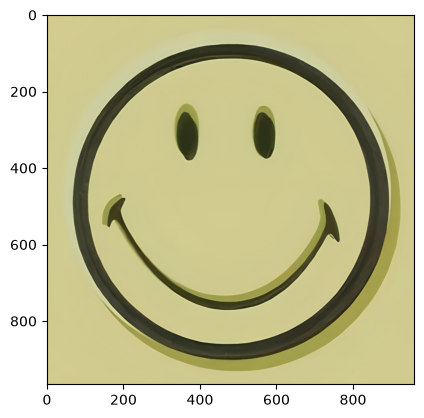

In [1274]:
img = cv.imread(face_example)

plt.imshow(img)
plt.show()

Al mostrar las imágenes con matplotlib los grafica como RGB cuando `opencv` lo lee como BGR. Vamos a sacar las máscaras para quedarnos únicamente con la información blanco y negro de las imágenes.

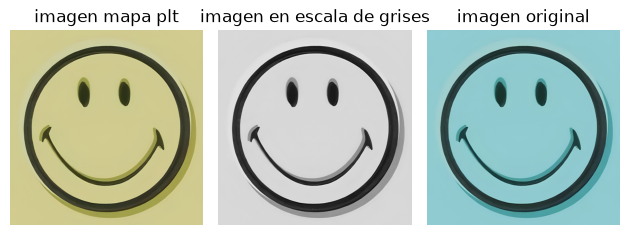

In [1275]:
imgGray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
imgColor = cv.cvtColor(img, cv.COLOR_BGR2RGB)

images = [img, imgGray, imgColor]
titles = ["imagen mapa plt", "imagen en escala de grises", "imagen original"]
gray = [False, True, False]

images_dict = {
    "images": [img, imgGray, imgColor],
    "titles": ["imagen mapa plt", "imagen en escala de grises", "imagen original"],
    "gray": [False, True, False]
}

plot_single_image(images=images_dict["images"], 
            titles=images_dict["titles"], 
            isgray=images_dict["gray"])

Ya con los mapas de colores clave, podemos empezar a mostrar únicamente la imagen en blanco y negro, lo cuál nos ayudará a la detección de las facciones. Para ello probamos diferentes métodos de "threshold" que proporciona `opencv`. Partimos de la base de la imagen en escalas de grises.

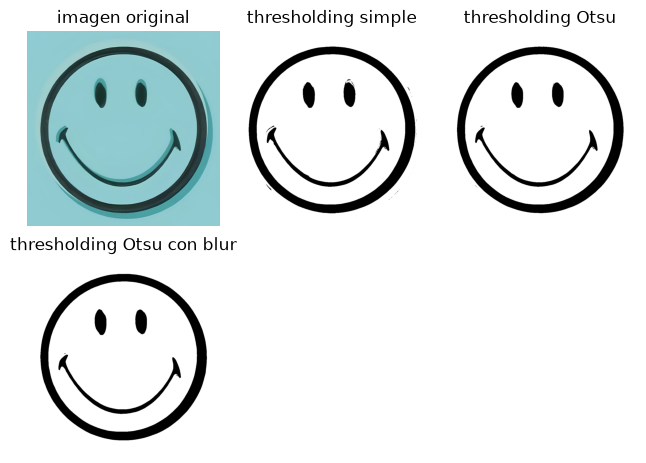

In [1276]:
#simple
ret,imgSimpleTh = cv.threshold(imgGray,127,255,cv.THRESH_BINARY)

#Otsu
ret2,imgOtsuTh = cv.threshold(imgGray,0,255,cv.THRESH_BINARY+cv.THRESH_OTSU)

#gaussiano + Otsu
blur = cv.GaussianBlur(imgGray,(5,5),0)
ret3,imgGaussTh = cv.threshold(blur,0,255,cv.THRESH_BINARY+cv.THRESH_OTSU)

threshold_images = {
    "images": [imgColor, imgSimpleTh, imgOtsuTh, imgGaussTh],
    "titles": ["imagen original", "thresholding simple", "thresholding Otsu", "thresholding Otsu con blur"],
    "gray": [False, True, True, True]
}

plot_single_image(images=threshold_images["images"], 
            titles=threshold_images["titles"], 
            isgray=threshold_images["gray"])

Claramente Otsu es el ganador, vamos a aplicarlo sobre todas las imágenes.

In [1277]:
for image in os.listdir(face_dir):
    img_path = os.path.join(face_dir, image)
    ret, img = process_Otsu_image(img_path=img_path)

    cv.imwrite(os.path.join(gray_processed, image), img)

print("Archivos guardados correctamente")

Archivos guardados correctamente


Vamos a ver el resultado de algunos

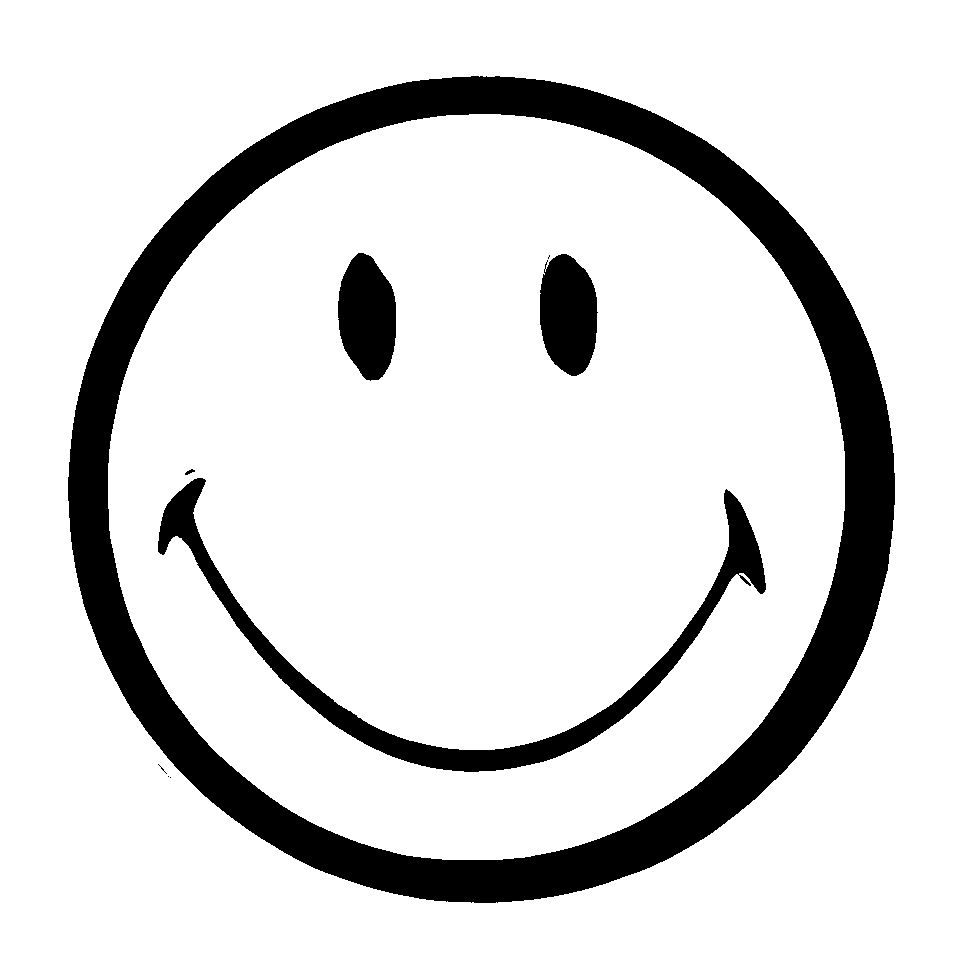

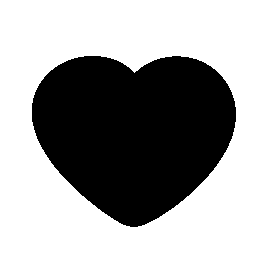

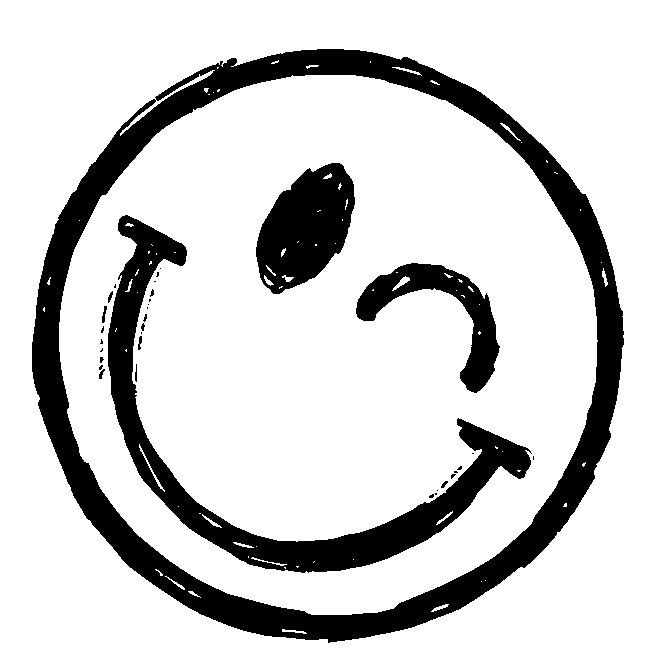

In [1278]:
images2display = ["blue", "f10_spo_heart", "f12_sws_wink"]

for image in images2display:
    display(Image(filename=f"{gray_processed}/{image}.png", width=200, height=200))

Solo se han mostrado 3 imágenes de ejemplo, la primera y la tercera están correctamente coloreadas en blanco y negro, sin embargo, la segunda (el corazón) no. Esto es debido a que los umbrales de Otsu no han sido lo suficientemente precisos para clasificar el color del relleno como no relevante. 
Vamos a probar otra técnica, pasaremos las imágenes a HSV y nos quedaremos con la tercera capa que indica el brillo de la imagen. Por tanto, al aplicarlo sobre la imagen, nos quedará en blanco y negro limpios.

Archivos guardados correctamente


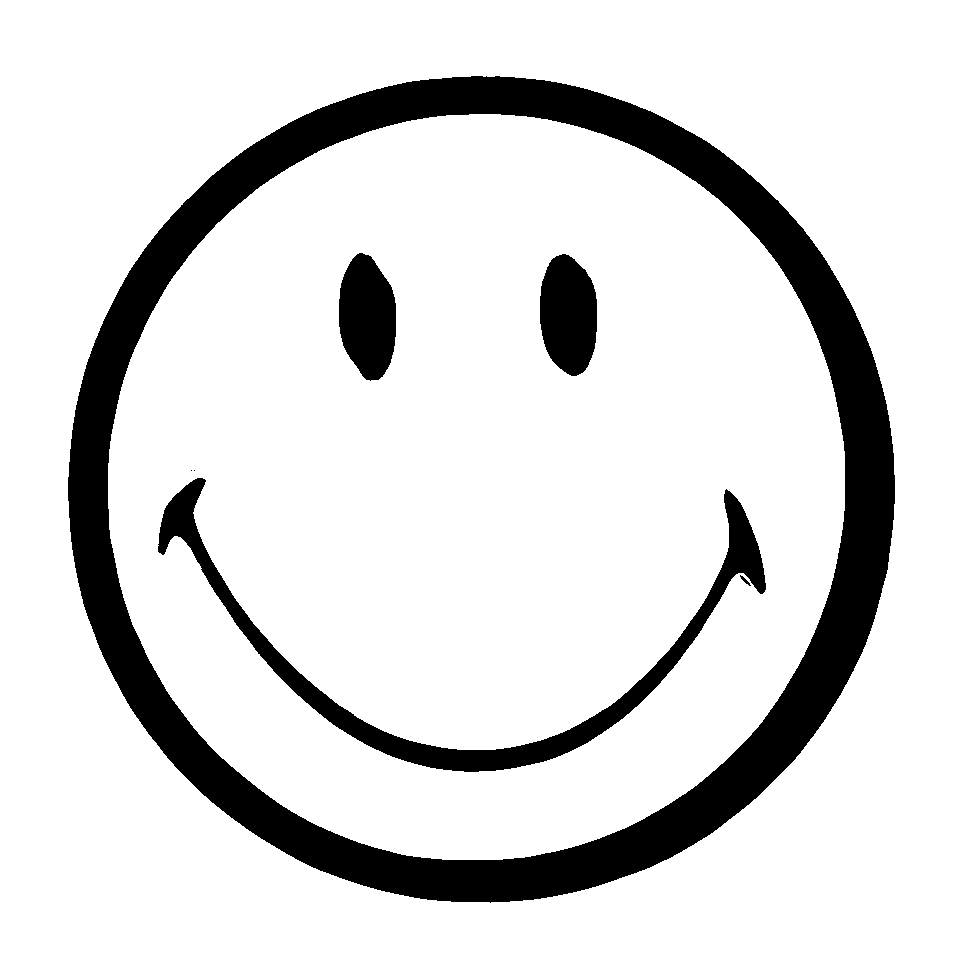

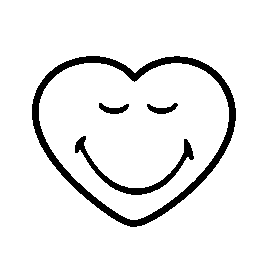

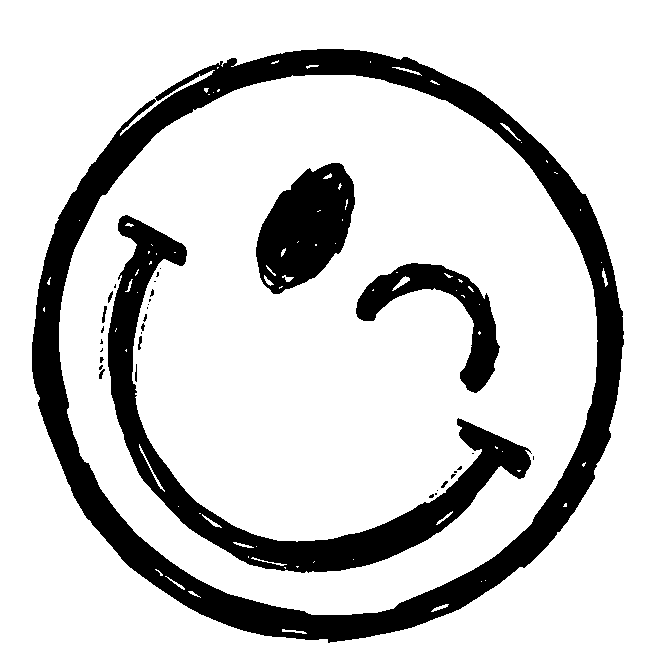

In [1279]:
BnW_images = []

for image in os.listdir(face_dir):
    img_path = os.path.join(face_dir, image)
    ret, img = process_HSV_image(img_path=img_path)

    BnW_images.append(img)
    
    cv.imwrite(os.path.join(hsv_processed, image), img)

print("Archivos guardados correctamente")

images2display = ["blue", "f10_spo_heart", "f12_sws_wink"]

for image in images2display:
    display(Image(filename=f"{hsv_processed}/{image}.png", width=200, height=200))

Ya estaría solucionado. Hemos almacenado todas las imagenes en una lista llamada "BnW_images" para más adelante aplicarle la detección.

## Reconocimiento de ojos

In [1280]:
def build_contours(mask):
    _, imgTh = cv.threshold(mask, 127, 255, cv.THRESH_BINARY_INV)
    contours, _ = cv.findContours(imgTh, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
    face = max(contours, key=cv.contourArea)
    return imgTh, contours, face

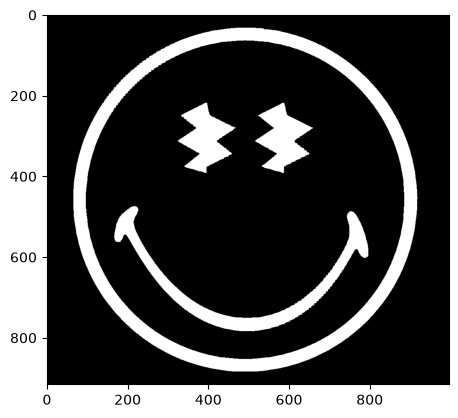

In [1281]:
imgTh, contours, face = build_contours(BnW_images[3])

plt.imshow(imgTh, cmap='gray')

# relleno = np.zeros_like(imgTh)
# draw = cv.drawContours(relleno, [face], -1, 255, thickness=cv.FILLED)

Probamos a detectar los hoyuelos con los puntos de Harris.

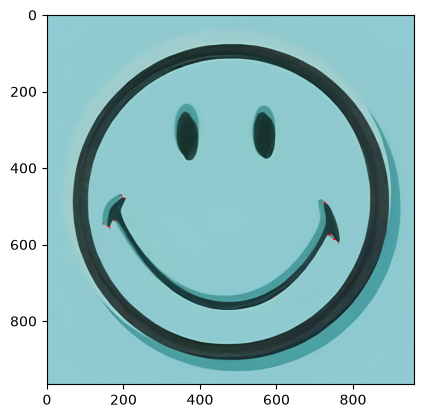

In [1282]:
gray = np.float32(imgGray)
dst = cv.cornerHarris(gray,2,3,0.04)

dst = cv.dilate(dst,None)

imgColor[dst>0.01*dst.max()]=[255,0,0]
plt.imshow(imgColor)

Probamos de otra forma, con la información que nos da el método `connectedComponentsWithStats`.

In [1283]:
filling = np.zeros_like(imgTh)
cv.drawContours(filling, [face], -1, 255, thickness=cv.FILLED)

connectivity = 8
num_labels, labels, stats, centroids = cv.connectedComponentsWithStats(imgTh , connectivity=connectivity , ltype=cv.CV_32S)

face_area = cv.countNonZero(filling)

candidates = []
for i in range(1, num_labels): #nos saltamos el fondo
    cx, cy = centroids[i]
    cx, cy = int(round(cx)), int(round(cy))
    if filling[cy, cx] > 0:
        candidates.append((i, stats[i, cv.CC_STAT_AREA]))

outer_ring = max(candidates, key=lambda num: num[1])
candidates = [num for num in candidates if num is not outer_ring]

NOISE_PERCENTAGE = 0.005
filtered_candidates = [num for num in candidates if num[1] > NOISE_PERCENTAGE*face_area]

if not filtered_candidates:
    print("FAIL")

mouth = max(filtered_candidates, key=lambda num: stats[num[0], cv.CC_STAT_WIDTH])
eyes = [num for num in filtered_candidates if num is not mouth]

Dentro de `labels` cogemos la que pertenece a la boca según los índices establecidos en el bucle.

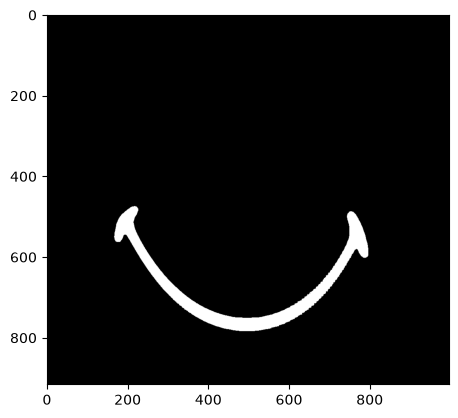

In [1284]:
mouth_idx = mouth[0] 
mouth_mask = (labels == mouth_idx).astype(np.uint8) * 255

plt.imshow(mouth_mask, cmap='gray')

Cortamos la imagen para quedarnos únicamente con la boca y realizamos eskeletonize para dejar la imagen como un único pixel y así poder detectar los hoyuelos mejor.

(310, 630) (np.int32(630), np.int32(310))


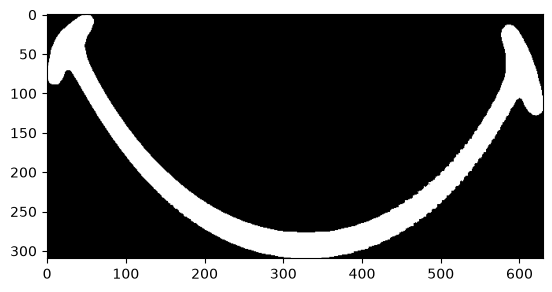

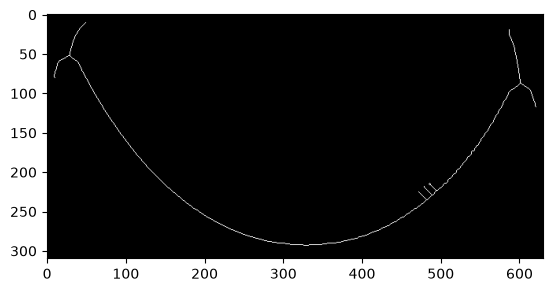

In [1285]:
from skimage.morphology import skeletonize

mouth_idx = mouth[0]
mouth_mask = (labels == mouth_idx).astype(np.uint8) * 255

x, y, w, h = stats[mouth_idx, :4]
mouth_crop = mouth_mask[y:y+h, x:x+w]

skel = skeletonize(mouth_crop > 0)

print(mouth_crop.shape, (w, h)) 
plt.imshow(mouth_crop, cmap='gray'); plt.show()
plt.imshow(skel, cmap='gray'); plt.show()

Calculamos la distacia entre cada punta para almacenar de punta a punta la boca detectada.

(np.int64(9), np.int64(76)) (np.int64(621), np.int64(117))


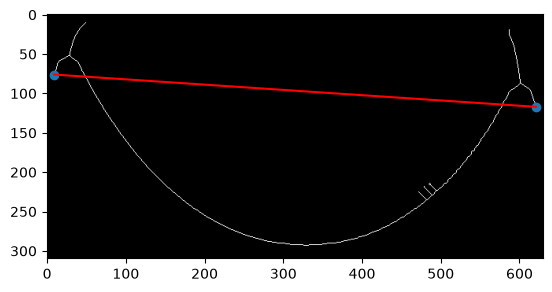

In [1286]:
ys, xs = np.nonzero(skel)

best_distance = 0
edge1 = 0
edge2 = 0

for a in range(len(xs)):
    for b in range(len(xs)):
        dx = xs[a] - xs[b]
        dy = ys[a] - ys[b]
        distance = (dy**2 + dx**2) ** 0.5

        if distance > best_distance:
            best_distance = distance
            edge1 = (xs[a], ys[a])
            edge2 = (xs[b], ys[b])

print(edge1, edge2)

plt.imshow(skel, cmap='gray')
plt.plot([edge1[0], edge2[0]], [edge1[1], edge2[1]], 'r-') 
plt.scatter([edge1[0], edge2[0]], [edge1[1], edge2[1]])

In [1287]:
MIN_BRANCH = 0.02
MAX_BRANCH = 0.25

def mouth_detection(skel, w, h):
    sk = (skel > 0).astype(np.uint8)

    neighbors = cv.filter2D(src=sk, ddepth=-1, kernel=np.ones((3, 3)), borderType=cv.BORDER_CONSTANT) - sk
    endpoints = ((sk==1) & (neighbors==1)).astype(np.uint8)
    cross = ((sk==1) & (neighbors>=3)).astype(np.uint8)

    num_crosses, _, _, crosses_centroids = cv.connectedComponentsWithStats(image=cross, connectivity=8)
    y_ep, x_ep = np.nonzero(endpoints)

    size = max(w, h)

    branches = {c: [] for c in range(1, num_crosses)}
    for k in range(len(x_ep)):
        best_cross, best_distance = None, None
        for c in range(1, num_crosses):
            cx, cy = crosses_centroids[c]
            distance = ((x_ep[k] - cx)**2 + (y_ep[k] - cy)**2) ** 0.5

            if best_distance is None or distance < best_distance:
                best_cross, best_distance = c, distance
        if best_cross is not None and (MIN_BRANCH <= best_distance/size <= MAX_BRANCH):
            branches[best_cross].append((x_ep[k], y_ep[k]))

    x_center, y_center = w/2, h/2
    states = []
    for c, points in branches.items():
        cx, cy = crosses_centroids[c]
        dx, dy = x_center - cx, y_center - cy #distancia de cada rama al centro de la boca

        sides = [dx * (py - cy) - dy * (px - cx) for (px, py) in points]

        if len(points) >= 2 and (max(sides) > 0 > min(sides)):
            states.append("Complete")
        elif len(points) >= 1:
            states.append("Half")

    completes = states.count("Complete")
    if completes == 2:
        return True, "completed"
    else:
        return False, f"completed are: {completes} of 2 states: {states}"

x, y, w, h =   stats[mouth_idx, :4]
okay, reason = mouth_detection(skel, w, h)
print(okay, reason)

True completed
